# The shift decision

EcoShift's scheduling question is which hours to run in, not the exact intensity of every hour.

For each complete local day, take the 4 hours the forecast says are cleanest, and the single hour it says is cleanest. **Regret** is the actual intensity of those hours minus the actual intensity of the hours that really were cleanest. The unit is still gCO₂/kWh.

A regret of 10 means a job placed in the forecast's clean window emits 10 grams more per kWh than a job placed in the true clean window. A 10 kWh job emits 100 grams more. Regret is zero when the order is right, even if every hour is 40 g/kWh too clean. MAE cannot say that.

`rank_corr` is the Spearman correlation of the 24 hours. It is 1 when the forecast has the day's order exactly right.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from src.carbon_data import load_model_frame
from src.modeling import (
    TARGET,
    day_scores,
    error_components,
    fixed_forecasts,
    local_day_labels,
    train_test_split,
)

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
forecasts = fixed_forecasts(train, test)
print(
    f"train through {train.index.max():%Y-%m-%d %H} UTC; "
    f"holdout {test.index.min():%Y-%m-%d %H} to {test.index.max():%Y-%m-%d %H} UTC "
    f"({len(test)} hours)"
)
print(
    f"mean carbon {train[TARGET].mean():.0f} g/kWh in training, "
    f"{test[TARGET].mean():.0f} on the holdout"
)
print("forecasts:", ", ".join(forecasts))


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

train through 2026-09-20 22 UTC; holdout 2026-09-20 23 to 2026-10-18 23 UTC (673 hours)
mean carbon 103 g/kWh in training, 172 on the holdout
forecasts: hour-of-day mean, yesterday, same hour, day-ahead ridge, day-ahead tree, previous hour


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

In [2]:
rows = []
store = {}
for name, predicted in forecasts.items():
    daily = day_scores(test, predicted)
    store[name] = daily
    rows.append(
        {
            "model": name,
            "regret_4h": daily["regret_4h"].mean(),
            "regret_1h": daily["regret_1h"].mean(),
            "rank_corr": daily["rank_corr"].mean(),
            "mae": daily["mae"].mean(),
        }
    )
decision = pd.DataFrame(rows).set_index("model").loc[list(forecasts)]
best_shift = decision["regret_4h"].idxmin()
best_mae = decision["mae"].idxmin()
print(f"Lowest 4-hour regret: {best_shift} at {decision.loc[best_shift, 'regret_4h']:.2f} g/kWh")
print(f"Lowest MAE: {best_mae} at {decision.loc[best_mae, 'mae']:.2f} g/kWh")
print(
    "A 10 kWh job in the day-ahead ridge's cleanest 4 hours emits "
    f"{10 * decision.loc['day-ahead ridge', 'regret_4h']:.0f} g more CO₂ than the true cleanest 4 hours, "
    "on the average holdout day."
)
decision.round(3)


Lowest 4-hour regret: previous hour at 0.78 g/kWh
Lowest MAE: previous hour at 10.06 g/kWh
A 10 kWh job in the day-ahead ridge's cleanest 4 hours emits 20 g more CO₂ than the true cleanest 4 hours, on the average holdout day.


,regret_4h,regret_1h,rank_corr,mae
model,,,,
hour-of-day mean,1.902,4.296,0.837,70.931
"yesterday, same hour",2.173,4.459,0.840,26.437
day-ahead ridge,1.987,3.160,0.860,24.887
day-ahead tree,2.455,5.033,0.839,30.717
previous hour,0.781,1.577,0.927,10.057


## A day the order survived, and a day it did not

Both panels are the day-ahead ridge. The title is that day's 4-hour regret.

/var/folders/g2/mv6w8l9x5412btq20l7_rg3w0000gn/T/ipykernel_60257/2690523975.py:21: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


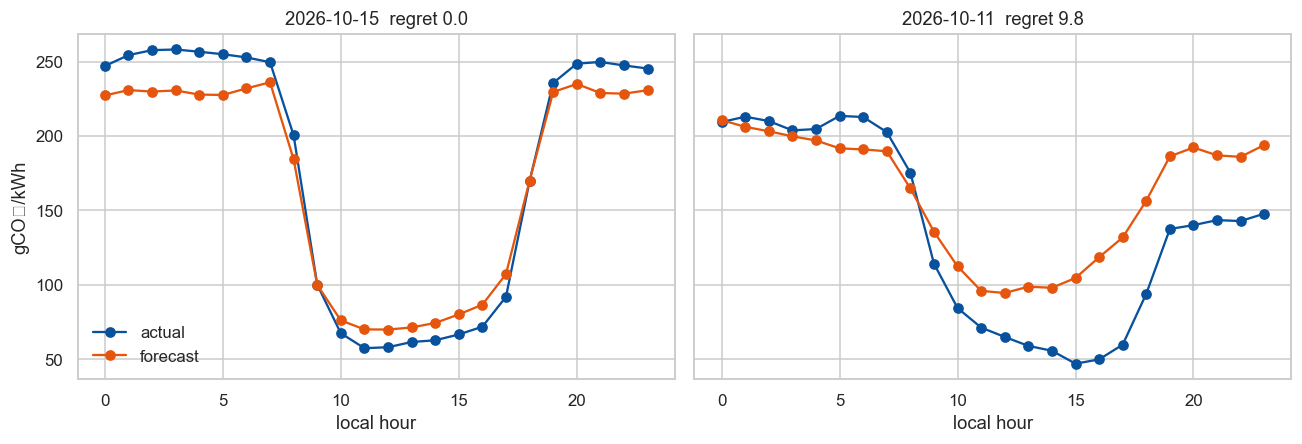

In [3]:
daily = store["day-ahead ridge"].sort_values("regret_4h")
examples = [daily.iloc[0], daily.iloc[-1]]
labels = local_day_labels(test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, row in zip(axes, examples):
    chosen = labels.to_numpy() == row["local_day"]
    hours = test.loc[chosen, "hour_local"]
    order = hours.to_numpy().argsort()
    ax.plot(hours.to_numpy()[order], test.loc[chosen, TARGET].to_numpy()[order], marker="o", label="actual", color="#08519c")
    ax.plot(
        hours.to_numpy()[order],
        forecasts["day-ahead ridge"][chosen][order],
        marker="o",
        label="forecast",
        color="#e6550d",
    )
    ax.set_title(f"{row['local_day']}  regret {row['regret_4h']:.1f}")
    ax.set_xlabel("local hour")
axes[0].set_ylabel("gCO₂/kWh")
axes[0].legend(frameon=False)
fig.tight_layout()
